# MeterTrace — Notebook 02: Data Preprocessing

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 2 of 8

## Purpose
Turn the raw SGCC file into clean, **leakage-safe** data that the next notebooks can load directly.
Every step is based on evidence from Notebook 01.

## Preprocessing decisions (approved by the team)
| # | Decision |
|---|---|
| 1 | Sort the daily columns chronologically and insert the absent day 18 Sep 2016 |
| 2 | Set 3 Oct 2014 to missing for **every** customer (only 15 customers had a reading that day, all labelled theft) |
| 3 | Keep the 5 empty customers in the customer table; document whether they can be used for modelling |
| 4 | Do not delete identical histories; keep each identical-history group **together** in one split |
| 5 | Investigate contradictory labels and apply a simple, documented policy |
| 6 | About 70 / 15 / 15 train / validation / test, preserving the theft share, respecting the groups |
| 7 | Record missing-reading indicators and ratios **before** any imputation |
| 8 | Investigate outliers; cap with a **training-derived** threshold only if justified |
| 9 | Simple, leakage-safe imputation |
| 10 | Transformations and scaling fitted on **training customers only** |

## Golden rule of this notebook
Anything that uses information from **more than one customer** (a cap, a mean, a standard deviation)
is computed from **training customers only** and then applied unchanged to validation and test.
Steps that use only **one customer's own readings** are safe to apply to everyone.

## Outputs (all in `data/processed/`, not committed to Git)
| File | Contents | Used by |
|---|---|---|
| `customers.csv` | One row per customer: label, split, identical-history group, missingness indicators, flags | All later notebooks |
| `daily_clean.parquet` | Daily kWh, sorted, 18 Sep 2016 inserted, 3 Oct 2014 blanked, capped, **not imputed** (NaN = missing) | NB03 features, NB07/NB08 plots |
| `weekly_train.npz`, `weekly_validation.npz`, `weekly_test.npz` | Weekly sequences (imputed, log-transformed, scaled), weekly observed-day fractions, labels, IDs | NB05 deep learning models |
| `preprocessing_params.json` | Every fitted parameter that future notebooks must reuse | All later notebooks |

Small summaries are also saved to `outputs/results/` (committed) so the numbers can be checked on GitHub.

## 0. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

In [2]:
# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
for folder in [PROCESSED_DIR, FIGURE_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Constants ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ID_COLUMN = "CONS_NO"
LABEL_COLUMN = "FLAG"
GLITCH_DATE = pd.Timestamp("2014-10-03")   # nearly empty day found in Notebook 01
ABSENT_DATE = pd.Timestamp("2016-09-18")   # calendar day with no column in the raw file

# Split: 20 equal folds -> 3 folds test (15%), 3 folds validation (15%), 14 folds train (70%)
N_FOLDS = 20
TEST_FOLDS = 3
VALIDATION_FOLDS = 3

CAP_PERCENTILE = 99.99   # outlier cap = this percentile of TRAINING readings
DAYS_PER_WEEK = 7

NORMAL_COLOR = "#2a78d6"
THEFT_COLOR = "#eb6834"
NEUTRAL_COLOR = "#52514e"
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 12)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Raw file:", RAW_PATH.relative_to(PROJECT_ROOT), "| exists:", RAW_PATH.exists())

pandas 3.1.0 | numpy 2.5.4
Raw file: data/raw/data.csv | exists: True


## 1. Load the raw data and sort the dates
Same as Notebook 01: read the file (read-only), turn the text column names into real dates, and sort
them. We work on an in-memory copy; the raw file is never changed.

In [3]:
raw_data = pd.read_csv(RAW_PATH)
date_columns = [column for column in raw_data.columns if column not in [ID_COLUMN, LABEL_COLUMN]]

daily = raw_data[date_columns].copy()
daily.index = raw_data[ID_COLUMN]
daily.columns = pd.to_datetime(pd.Series(date_columns), format="%Y/%m/%d")
daily = daily.sort_index(axis=1)

labels = pd.Series(raw_data[LABEL_COLUMN].to_numpy(), index=raw_data[ID_COLUMN], name=LABEL_COLUMN)

print("Raw shape:", raw_data.shape)
print("Daily table:", daily.shape, "| chronological:", daily.columns.is_monotonic_increasing)
print("Labels:", labels.value_counts().sort_index().to_dict())

Raw shape: (42372, 1036)
Daily table: (42372, 1034) | chronological: True
Labels: {0: 38757, 1: 3615}


## 2. Insert the absent day (18 Sep 2016)
The file has 1,034 daily columns for 1,035 calendar days. We re-index the columns to the full calendar,
which inserts 18 Sep 2016 as an empty column. Now every position in the table is exactly one calendar
day, so every week we build later really contains 7 consecutive days.

In [4]:
full_calendar = pd.date_range(daily.columns.min(), daily.columns.max(), freq="D")
daily = daily.reindex(columns=full_calendar)

print("Daily table after inserting the absent day:", daily.shape)
print("Readings on", ABSENT_DATE.date(), ":", int(daily[ABSENT_DATE].notna().sum()), "(empty, as expected)")

Daily table after inserting the absent day: (42372, 1035)
Readings on 2016-09-18 : 0 (empty, as expected)


## 3. Blank out 3 Oct 2014 for every customer
Notebook 01 found that only 15 customers have a reading on this day, and **all 15 are labelled theft**.
If we kept these readings, "has a reading on 3 Oct 2014" would be a perfect but meaningless theft
signal: a **label leak**. Setting the whole day to missing is a row-wise operation, so it is safe to
apply to everyone. We do it **first**, before any indicator or feature is computed.

In [5]:
has_glitch_reading = daily[GLITCH_DATE].notna()
print("Readings removed on", GLITCH_DATE.date(), ":", int(has_glitch_reading.sum()),
      "| labels of those customers:", labels[has_glitch_reading].value_counts().to_dict())

daily[GLITCH_DATE] = np.nan
print("Readings left on", GLITCH_DATE.date(), ":", int(daily[GLITCH_DATE].notna().sum()))

Readings removed on 2014-10-03 : 15 | labels of those customers: {1: 15}
Readings left on 2014-10-03 : 0


## 4. Record missingness **before** any imputation (decision D3/D4)
Notebook 01 showed that missing readings carry information (theft customers have more of them).
Imputation would hide this, so we record it now, per customer:

- `observed_days`: days with a real reading,
- `missing_ratio`: share of days without a reading, counted over the **1,033 days that could have a
  reading** (we leave out 18 Sep 2016 and 3 Oct 2014, which are missing for everybody by construction),
- `first_reading_date`: when the meter started reporting.

The day-by-day missing indicator is kept too: in `daily_clean.parquet` every missing day stays `NaN`.

In [6]:
days_that_could_have_data = ~daily.columns.isin([ABSENT_DATE, GLITCH_DATE])
n_possible_days = int(days_that_could_have_data.sum())

has_reading = daily.notna()
observed_days = has_reading.sum(axis=1)
missing_ratio = 1 - observed_days / n_possible_days

has_any_reading = observed_days > 0
first_reading_date = pd.Series(pd.NaT, index=daily.index)
first_reading_date[has_any_reading] = has_reading.loc[has_any_reading].idxmax(axis=1)

print("Days that could have a reading:", n_possible_days)
missing_by_class = pd.DataFrame({
    "Normal": missing_ratio[labels == 0].describe(),
    "Theft": missing_ratio[labels == 1].describe(),
}).round(3)
missing_by_class

Days that could have a reading: 1033


,Normal,Theft
count,38757.000,3615.000
mean,0.250,0.314
std,0.288,0.293
min,0.000,0.000
25%,0.012,0.021
50%,0.092,0.213
75%,0.579,0.706
max,1.000,1.000


## 5. The five customers with no readings (decision 3)
We keep them in the customer table so that every one of the 42,372 customers is accounted for.
The question is whether they can be used for **training** or **evaluation**.

In [7]:
has_no_readings = observed_days == 0
empty_table = pd.DataFrame({"Label (1 = theft)": labels[has_no_readings], "Observed days": observed_days[has_no_readings]})
print("Customers with no readings:", int(has_no_readings.sum()))
empty_table

Customers with no readings: 5


,Label (1 = theft),Observed days
CONS_NO,,
58C5C2F9D81EA5DC8421CACB0C73E495,1,0
6BE983A5063B5DF9225ADD95AD3F241B,1,0
2B981D4283253BA362DB2915358B88BF,1,0
D176EB392233366F6F38E46AA592154E,0,0
A63E94C418356023D70BE00B7FE2C4EE,0,0


**Can these 5 customers be used?**
- **Training: no.** They have 0 observed days, so there is no consumption pattern to learn from.
- **Evaluation: no.** No feature can be computed and no weekly value exists. Imputing would mean
  inventing a complete 2.8-year history, and any score a model gave them would be meaningless.

**Decision.** They stay in `customers.csv` (so all 42,372 customers are accounted for) with
`split = "excluded (no readings)"` and `has_no_readings = True`. They are **not** included in any
model-ready file. This removes 3 theft and 2 normal labels from modelling.

In a real deployment, a meter that never reports is itself worth a visit, so these customers would go
straight to manual inspection rather than to a model.

## 6. Identical consumption histories (decision 4)
As in Notebook 01, we give every customer a **fingerprint** of their full daily history (missing days
written as -1 so that gaps on the same days also match). Customers with the same fingerprint form an
**identical-history group**. Every customer gets a group number; most groups contain just one customer.

We use the cleaned table (after Steps 2 and 3), because that is what the models will see.

In [8]:
fingerprint = pd.util.hash_pandas_object(daily.fillna(-1), index=False)
fingerprint.index = daily.index

history_group = pd.Series(pd.factorize(fingerprint)[0], index=daily.index, name="history_group")
group_size = history_group.map(history_group.value_counts())

shares_history = group_size > 1
print("Customers sharing their history with at least one other customer:", int(shares_history.sum()))
print("Groups with more than one customer:", history_group[shares_history].nunique())
print("Customers in such groups, excluding the 5 empty customers:", int((shares_history & ~has_no_readings).sum()))
print("Largest group size:", int(group_size.max()))

Customers sharing their history with at least one other customer: 1014
Groups with more than one customer: 136
Customers in such groups, excluding the 5 empty customers: 1009
Largest group size: 398


## 7. Contradictory labels inside identical-history groups (decision 5)
A group is **contradictory** when identical histories carry both labels.

In [9]:
group_theft_count = labels.groupby(history_group).sum()
group_total = history_group.value_counts().sort_index()
group_normal_count = group_total - group_theft_count
contradictory_groups = group_theft_count.index[(group_theft_count > 0) & (group_normal_count > 0)]

in_contradictory_group = history_group.isin(contradictory_groups)

contradictory_table = pd.DataFrame({
    "Customers": group_total[contradictory_groups],
    "Theft labels": group_theft_count[contradictory_groups],
    "Normal labels": group_normal_count[contradictory_groups],
    "Observed days": observed_days.groupby(history_group).first()[contradictory_groups],
    "Days above 0 kWh": (daily > 0).sum(axis=1).groupby(history_group).first()[contradictory_groups],
}).sort_values("Customers", ascending=False).reset_index(drop=True)
contradictory_table.index = [f"Group {number + 1}" for number in range(len(contradictory_table))]

print("Contradictory groups:", len(contradictory_groups))
print("Customers in contradictory groups:", int(in_contradictory_group.sum()),
      "| theft:", int(labels[in_contradictory_group].sum()),
      "| normal:", int((labels[in_contradictory_group] == 0).sum()))
contradictory_table

Contradictory groups: 5
Customers in contradictory groups: 497 | theft: 18 | normal: 479


,Customers,Theft labels,Normal labels,Observed days,Days above 0 kWh
Group 1,398,11,387,304,0
Group 2,60,2,58,1033,0
Group 3,31,1,30,588,0
Group 4,5,3,2,0,0
Group 5,3,1,2,32,0


### Our policy for contradictory labels
We considered three simple options:

| Option | Problem |
|---|---|
| Delete every contradictory group | Throws away hundreds of customers, including one large group, because of a few conflicting labels |
| Change labels to the group's majority label | We would be **inventing** ground truth; we do not know how the labels were assigned |
| **Keep every customer with its original label, and keep each group inside one split** | Some label noise remains, but nothing is invented or hidden |

**We choose the third option.** It is the most honest one, and grouping (next section) makes sure that
identical histories can never appear in both the training data and the evaluation data. The cost:
identical inputs always receive identical scores, so no model can be fully right on a contradictory
group. We flag these customers (`in_contradictory_group` in `customers.csv`) so this limitation can be
reported in the evaluation.

**What we see.**
- 5 groups with contradictory labels, containing 497 customers (18 theft, 479 normal).
- **In all five groups, no customer has a single reading above 0 kWh** ("Days above 0 kWh" = 0). They are
  either all-zero or completely empty meters (Group 4 is the 5 empty customers from Section 5, which are
  excluded anyway).
- So the conflicting labels are attached to histories that contain **no consumption at all**. Nothing in
  the readings can explain why some of these customers are labelled theft. This is a limitation of the
  labels, and we will mention it when we report results.

## 8. Train / validation / test split (decisions 4 and 6)

### The trade-off
We want three things at once:
1. about **70 / 15 / 15** of customers,
2. the **same theft share** in every split (stratification), and
3. every identical-history group **entirely inside one split** (no leakage between splits).

A normal stratified split cannot guarantee point 3. scikit-learn's `StratifiedGroupKFold` does all
three approximately: it divides the customers into folds of similar size and theft share, and it never
splits a group across folds. We ask for **20 folds** (5% each) and then use

- folds 0–2 → **test** (15%)
- folds 3–5 → **validation** (15%)
- folds 6–19 → **train** (70%)

Because whole groups have to move together, the sizes and theft shares can only be approximately equal.
The tables below show how close they are.

The 5 customers with no readings are **not** given a split (Section 5).

In [10]:
modelling_customers = daily.index[~has_no_readings]
modelling_labels = labels[modelling_customers].to_numpy()
modelling_groups = history_group[modelling_customers].to_numpy()

fold_number = np.full(len(modelling_customers), -1)
fold_maker = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (_, fold_positions) in enumerate(fold_maker.split(np.zeros(len(modelling_customers)), modelling_labels, modelling_groups)):
    fold_number[fold_positions] = fold

split_name = np.where(fold_number < TEST_FOLDS, "test",
                      np.where(fold_number < TEST_FOLDS + VALIDATION_FOLDS, "validation", "train"))

split = pd.Series("excluded (no readings)", index=daily.index, name="split")
split[modelling_customers] = split_name

print("Customers per fold (min / max):", np.bincount(fold_number).min(), "/", np.bincount(fold_number).max())

Customers per fold (min / max): 2118 / 2119


In [11]:
split_summary = pd.DataFrame({
    "Customers": split.value_counts(),
    "Theft": labels.groupby(split).sum(),
})
split_summary["Normal"] = split_summary["Customers"] - split_summary["Theft"]
split_summary["Share of customers (%)"] = (split_summary["Customers"] / len(labels) * 100).round(2)
split_summary["Theft share (%)"] = (split_summary["Theft"] / split_summary["Customers"] * 100).round(2)
split_summary["Customers in contradictory groups"] = in_contradictory_group.groupby(split).sum()
split_summary["Customers sharing a history"] = (shares_history & ~has_no_readings).groupby(split).sum()
split_summary = split_summary.loc[["train", "validation", "test", "excluded (no readings)"]]
split_summary

,Customers,Theft,Normal,Share of customers (%),Theft share (%),Customers in contradictory groups,Customers sharing a history
split,,,,,,,
train,29657,2530,27127,69.99,8.53,401,793
validation,6354,540,5814,15.00,8.50,0,92
test,6356,542,5814,15.00,8.53,91,124
excluded (no readings),5,3,2,0.01,60.00,5,0


### Leakage checks
These checks must all print `True`. If any prints `False`, the split is broken and must not be used.

In [12]:
train_ids = set(split.index[split == "train"])
validation_ids = set(split.index[split == "validation"])
test_ids = set(split.index[split == "test"])

splits_per_group = split[~has_no_readings].groupby(history_group[~has_no_readings]).nunique()

print("No customer is in two splits:          ",
      len(train_ids & validation_ids) == 0 and len(train_ids & test_ids) == 0 and len(validation_ids & test_ids) == 0)
print("Every identical-history group is in one split:", bool((splits_per_group == 1).all()))
print("Every non-empty customer has a split:   ", len(train_ids) + len(validation_ids) + len(test_ids) == len(modelling_customers))

No customer is in two splits:           True
Every identical-history group is in one split: True
Every non-empty customer has a split:    True


**What we see.**
- **Sizes:** train 29,657 (69.99%), validation 6,354 (15.00%), test 6,356 (15.00%). Every fold has
  2,118 or 2,119 customers.
- **Theft share:** 8.53% in train, 8.50% in validation and 8.53% in test, almost identical to the full
  dataset's 8.53%.
- **Leakage checks:** all three print `True`. No customer and no identical-history group appears in
  more than one split.

Keeping groups together cost almost nothing here, because nearly all groups contain only one customer.

**Worth knowing for the evaluation.**
- The test set contains 91 customers from contradictory-label groups: the 60- and 31-customer all-zero
  groups, with 3 theft labels between them.
- Identical inputs always get identical scores, so each model will be wrong on some of them whatever it
  does.
- They are 1.4% of the test set and are flagged in `customers.csv`.

## 9. Extreme readings: investigate on training customers, then cap (decision 8)
From here on, anything computed **across customers** uses **training customers only**.

Notebook 01 showed isolated readings of hundreds of thousands of kWh for customers whose normal day is a
few kWh. Before choosing a cap, we look at the distribution of **training** readings.

In [13]:
is_train = (split == "train").to_numpy()
train_values = daily.to_numpy()[is_train]
train_observed_values = train_values[~np.isnan(train_values)]

percentile_levels = [50, 99, 99.9, 99.99, 99.999, 100]
train_percentiles = pd.DataFrame({
    "Training readings (kWh)": np.percentile(train_observed_values, percentile_levels),
    "Readings above this value": [int((train_observed_values > value).sum())
                                  for value in np.percentile(train_observed_values, percentile_levels)],
}, index=["50th (median)", "99th", "99.9th", "99.99th", "99.999th", "Maximum"]).round(2)
print("Observed training readings:", f"{train_observed_values.size:,}")
train_percentiles

Observed training readings: 22,741,022


,Training readings (kWh),Readings above this value
50th (median),4.58,11367505
99th,69.81,227357
99.9th,368.34,22742
99.99th,2112.00,2274
99.999th,11053.52,228
Maximum,466714.40,0


In [14]:
CAP_VALUE = float(np.percentile(train_observed_values, CAP_PERCENTILE))
print(f"Cap = {CAP_PERCENTILE}th percentile of training readings = {CAP_VALUE:.2f} kWh/day")

customer_median_day = daily.median(axis=1)
cap_impact = pd.DataFrame({
    "Readings above the cap": (daily > CAP_VALUE).sum(axis=1).groupby(split).sum(),
    "Customers with any reading above the cap": (daily > CAP_VALUE).any(axis=1).groupby(split).sum(),
    "Customers whose MEDIAN day is above the cap": (customer_median_day > CAP_VALUE).groupby(split).sum(),
}).loc[["train", "validation", "test"]]
cap_impact

Cap = 99.99th percentile of training readings = 2112.00 kWh/day


,Readings above the cap,Customers with any reading above the cap,Customers whose MEDIAN day is above the cap
split,,,
train,2274,181,4
validation,147,36,0
test,477,47,0


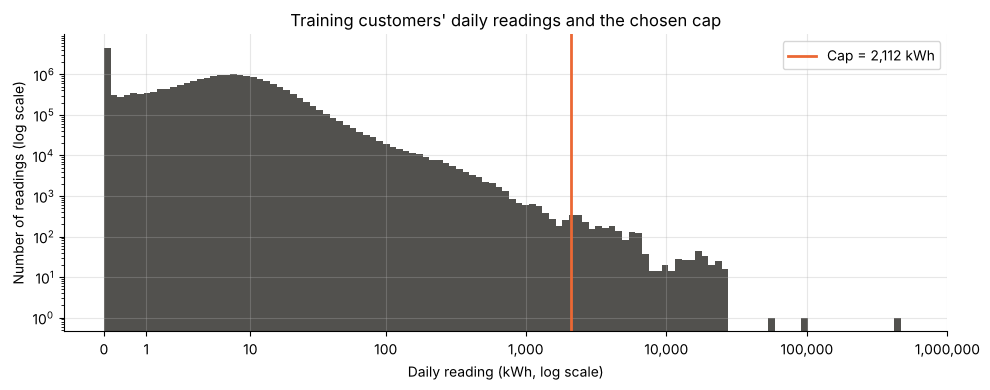

In [15]:
fig, ax = plt.subplots()
ax.hist(np.log10(train_observed_values + 1), bins=120, color=NEUTRAL_COLOR)
ax.axvline(np.log10(CAP_VALUE + 1), color=THEFT_COLOR, linewidth=2, label=f"Cap = {CAP_VALUE:,.0f} kWh")
ax.set_yscale("log")
tick_values = np.array([0, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000])
ax.set_xticks(np.log10(tick_values + 1))
ax.set_xticklabels([f"{value:,}" for value in tick_values])
ax.set_xlabel("Daily reading (kWh, log scale)")
ax.set_ylabel("Number of readings (log scale)")
ax.set_title("Training customers' daily readings and the chosen cap")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_training_readings_cap.png", dpi=120)
plt.show()

**What we see (training customers only).**
- **Spread:** the median training reading is 4.58 kWh. The 99th percentile is 69.81 kWh, the 99.9th
  368.34 kWh, the 99.99th 2,112.00 kWh, and the maximum 466,714.40 kWh.
- **Where the extremes are:** the histogram falls smoothly up to roughly 30,000 kWh. Beyond that there are
  a handful of isolated readings near 50,000, 100,000 and 470,000 kWh. Notebook 01 showed that such values
  sit next to normal days of a few kWh, so they are recording errors.

**Is a cap justified? Yes.** A single 466,714 kWh reading would dominate any average, standard deviation
or scaling. We cap at the **99.99th percentile of training readings = 2,112.00 kWh/day**:
- In training, 2,274 readings (0.01%) are capped, in 181 of 29,657 customers.
- The same value, computed without looking at validation or test, caps 147 readings (36 customers) in
  validation and 477 readings (47 customers) in test.
- **Known cost:** 4 training customers have a *median* day above the cap. They are genuinely very large
  consumers, and capping flattens much of their series. We accept this for 4 of 29,657 customers in
  exchange for removing errors that are hundreds of times larger.
- The `log1p` transform in Section 13 then reduces the skew that remains below the cap.

### Apply the cap to all customers
The **same** training-derived value is applied to train, validation and test. `clip` keeps missing values
missing.

In [16]:
daily_capped = daily.clip(upper=CAP_VALUE)

print("Maximum reading before capping:", f"{np.nanmax(daily.to_numpy()):,.2f} kWh")
print("Maximum reading after capping: ", f"{np.nanmax(daily_capped.to_numpy()):,.2f} kWh")
print("Missing cells unchanged:", int(daily.isna().sum().sum()) == int(daily_capped.isna().sum().sum()))

Maximum reading before capping: 800,003.32 kWh
Maximum reading after capping:  2,112.00 kWh


Missing cells unchanged: True


## 10. Save the cleaned daily table (not imputed)
This is the main input for feature engineering in Notebook 03 and for plots in Notebooks 07 and 08.
Missing days stay `NaN`, which is our day-by-day **missing indicator**. Parquet needs text column
names, so dates are stored as `YYYY-MM-DD`.

In [17]:
daily_to_save = daily_capped.copy()
daily_to_save.columns = daily_to_save.columns.strftime("%Y-%m-%d")
daily_to_save.to_parquet(PROCESSED_DIR / "daily_clean.parquet")

print("Saved daily_clean.parquet:", daily_to_save.shape,
      f"| {(PROCESSED_DIR / 'daily_clean.parquet').stat().st_size / 1e6:.1f} MB")

Saved daily_clean.parquet: (42372, 1035) | 73.0 MB


## 11. Weekly sequences for the deep learning models
Our report specifies that the LSTM reads a **weekly** consumption sequence (to keep training fast); the
autoencoder will use the same weekly vector. We cut the 1,035 days into consecutive 7-day blocks starting
on 1 Jan 2014: 147 full weeks plus a final block of 6 days, so **148 weeks**.

For each customer and week we compute:
- `weekly_kwh`: the **average of the observed days** in that week. A week with only a few missing days
  still gets a real value, so short gaps need no imputation at all.
- `weekly_observed`: the **share of the week's days that had a reading** (0 to 1). This is the weekly
  missing indicator; it lets models see which weeks were filled in.

In [18]:
n_days = daily_capped.shape[1]
week_of_day = np.arange(n_days) // DAYS_PER_WEEK
n_weeks = int(week_of_day.max()) + 1
week_start_dates = daily_capped.columns[::DAYS_PER_WEEK]

weekly_kwh_columns = {}
weekly_observed_columns = {}
for week in range(n_weeks):
    days_in_week = daily_capped.columns[week_of_day == week]
    weekly_kwh_columns[week] = daily_capped[days_in_week].mean(axis=1)              # NaN if no observed day
    weekly_observed_columns[week] = daily_capped[days_in_week].notna().mean(axis=1)

weekly_kwh = pd.DataFrame(weekly_kwh_columns)
weekly_observed = pd.DataFrame(weekly_observed_columns)

print("Weeks:", n_weeks, "| first week starts", week_start_dates[0].date(), "| last week starts", week_start_dates[-1].date())
print("Weekly table:", weekly_kwh.shape)
print("Days in the last week:", int((week_of_day == n_weeks - 1).sum()))

Weeks: 148 | first week starts 2014-01-01 | last week starts 2016-10-26
Weekly table: (42372, 148)
Days in the last week: 6


In [19]:
week_has_no_reading = weekly_kwh.isna()
modelling_rows = ~has_no_readings.to_numpy()

empty_week_share = pd.DataFrame({
    "Daily cells missing (%)": daily_capped.loc[modelling_rows].isna().to_numpy().mean() * 100,
    "Weekly cells with no reading (%)": week_has_no_reading.loc[modelling_rows].to_numpy().mean() * 100,
}, index=["Customers with readings"]).round(2)
empty_week_share

,Daily cells missing (%),Weekly cells with no reading (%)
Customers with readings,25.7,24.32


## 12. Imputation of the remaining empty weeks (decision 9)
Some weeks have no reading at all (mostly the long period before a meter's first reading). We fill them
using **only that customer's own data**:

1. **Gaps between two observed weeks** → straight-line (linear) interpolation between the neighbouring
   observed weeks.
2. **Gaps at the start or end** (for example before the first reading) → copy the nearest observed week
   (`bfill` for the start, `ffill` for the end).

Why this method?
- It is simple: three pandas methods.
- It keeps each customer's own consumption level (filling with a population median would make a large
  consumer suddenly look average).
- It is **leakage-safe by construction**: no statistic is computed across customers, so nothing needs to be
  "fitted on training data".
- The imputed weeks are **not hidden**: `weekly_observed = 0` marks them, and `missing_ratio` was recorded
  before imputation.

The 5 customers with no readings cannot be imputed (there is nothing to copy) and stay excluded.

In [20]:
weekly_interpolated = weekly_kwh.interpolate(axis=1, limit_area="inside")   # 1. gaps between observed weeks
weekly_imputed = weekly_interpolated.bfill(axis=1)                          # 2a. gaps at the start
weekly_imputed = weekly_imputed.ffill(axis=1)                               # 2b. gaps at the end

print("Missing weekly values left (customers with readings):",
      int(weekly_imputed.loc[modelling_rows].isna().sum().sum()))
print("Missing weekly values left (the 5 empty customers):",
      int(weekly_imputed.loc[~modelling_rows].isna().sum().sum()))

imputed_share = pd.DataFrame({
    "Weekly values imputed (%)": (week_has_no_reading.mean(axis=1) * 100).groupby(split).mean(),
}).loc[["train", "validation", "test"]].round(2)
imputed_share

Missing weekly values left (customers with readings): 0
Missing weekly values left (the 5 empty customers): 740


,Weekly values imputed (%)
split,
train,24.53
validation,24.40
test,23.25


**What we see.**
- 25.70% of daily cells are missing, but 24.32% of weekly cells are still empty after averaging.
  Weekly averaging fills only the short gaps, because most missingness is long stretches before a meter
  started reporting (Notebook 01).
- After imputation, no customer with readings has a missing weekly value. The 5 empty customers still
  have all 148 weeks missing (740 values), as expected, and stay excluded.
- About a quarter of weekly values are imputed in every split (24.53% train, 24.40% validation,
  23.25% test).

**Limitation to remember.**
- For a late starter, the imputed start of the series is a flat copy of their first observed week.
- A sequence model can notice "flat at the start" just as a feature model can use the missing ratio.
  Both encode the same fact: this meter started reporting late. That fact is genuinely linked to the
  label in this dataset (Notebook 01), and it uses no information from other customers.
- It is not leakage, but we should describe it honestly when explaining what the models learned.
- The `observed` array marks every imputed week with 0.

### Example: what imputation does to one customer
We pick a training customer with real (non-zero) consumption, a late start, and some gaps in the middle.
Grey dots are real weekly averages; coloured dots are filled-in weeks.

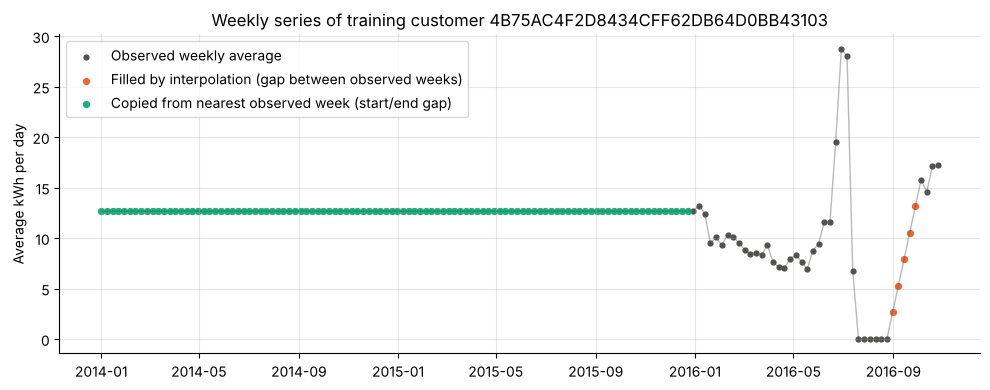

In [21]:
filled_by_interpolation = week_has_no_reading & weekly_interpolated.notna()
filled_from_edge = weekly_interpolated.isna()

example_candidates = split.index[
    (split == "train").to_numpy()
    & (filled_by_interpolation.sum(axis=1) >= 3).to_numpy()
    & (filled_from_edge.sum(axis=1) >= 20).to_numpy()
    & (weekly_kwh.median(axis=1) > 3).to_numpy()
]
example_customer = example_candidates[0]

example_series = weekly_imputed.loc[example_customer]
fig, ax = plt.subplots()
ax.plot(week_start_dates, example_series, color=NEUTRAL_COLOR, linewidth=1, alpha=0.4)
ax.scatter(week_start_dates, weekly_kwh.loc[example_customer], color=NEUTRAL_COLOR, s=12,
           label="Observed weekly average")
ax.scatter(week_start_dates, example_series.where(filled_by_interpolation.loc[example_customer]),
           color=THEFT_COLOR, s=18, label="Filled by interpolation (gap between observed weeks)")
ax.scatter(week_start_dates, example_series.where(filled_from_edge.loc[example_customer]),
           color="#1baf7a", s=18, label="Copied from nearest observed week (start/end gap)")
ax.set_ylabel("Average kWh per day")
ax.set_title(f"Weekly series of training customer {example_customer}")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_imputation_example.png", dpi=120)
plt.show()

## 13. Log transform and scaling (decision 10)
Weekly averages are still very skewed (most are a few kWh, a few are hundreds). Neural networks train
better on values of similar size, so we:

1. apply `log1p(x) = log(1 + x)`, which shrinks large values and keeps 0 at 0;
2. standardise with **one mean and one standard deviation computed from training customers only**:
   `scaled = (log1p(x) - train_mean) / train_std`.

Using a single mean and standard deviation for all weeks keeps the **shape** of each sequence unchanged
(every week is transformed in the same way).

In [22]:
weekly_log = np.log1p(weekly_imputed)

train_rows = (split == "train").to_numpy()
LOG_TRAIN_MEAN = float(weekly_log.loc[train_rows].to_numpy().mean())
LOG_TRAIN_STD = float(weekly_log.loc[train_rows].to_numpy().std())

weekly_scaled = (weekly_log - LOG_TRAIN_MEAN) / LOG_TRAIN_STD

print(f"Training log1p mean = {LOG_TRAIN_MEAN:.4f}, std = {LOG_TRAIN_STD:.4f}")

# Train should be exactly mean 0 / std 1; validation and test should be close (not exact)
scaled_check_rows = []
for split_to_check in ["train", "validation", "test"]:
    split_values = weekly_scaled.loc[(split == split_to_check).to_numpy()].to_numpy()
    scaled_check_rows.append({"split": split_to_check, "Mean after scaling": split_values.mean(),
                              "Std after scaling": split_values.std()})
scaled_check = pd.DataFrame(scaled_check_rows).set_index("split").round(3)
scaled_check

Training log1p mean = 1.6018, std = 1.1036


,Mean after scaling,Std after scaling
split,,
train,-0.000,1.000
validation,0.026,1.004
test,0.004,0.997


**What we see.**
- **Fitted parameters:** the log1p mean is 1.6018 and the standard deviation 1.1036, both computed from
  training customers only.
- **Training data:** after scaling it has mean 0.000 and standard deviation 1.000 (by construction).
- **Validation and test:** they come out close but not exact (validation 0.026 / 1.004, test
  0.004 / 0.997).

Validation and test *should not* be exactly 0 and 1. If they were, the scaler would have been fitted on
them, which would be leakage. Values this close show that the three splits have very similar
distributions.

## 14. Save the processed outputs

### 14a. Customer table
One row per customer (all 42,372), so every later notebook uses exactly the same split.

In [23]:
customers = pd.DataFrame({
    LABEL_COLUMN: labels,
    "split": split,
    "history_group": history_group,
    "history_group_size": group_size,
    "in_contradictory_group": in_contradictory_group,
    "has_no_readings": has_no_readings,
    "observed_days": observed_days,
    "missing_ratio": missing_ratio.round(6),
    "first_reading_date": first_reading_date.dt.strftime("%Y-%m-%d"),
    "weekly_imputed_share": week_has_no_reading.mean(axis=1).round(6),
})
customers.index.name = ID_COLUMN
customers.to_csv(PROCESSED_DIR / "customers.csv")
print("Saved customers.csv:", customers.shape)
customers.head()

Saved customers.csv: (42372, 10)


,FLAG,split,history_group,history_group_size,in_contradictory_group,has_no_readings,observed_days,missing_ratio,first_reading_date,weekly_imputed_share
CONS_NO,,,,,,,,,,
0387DD8A07E07FDA6271170F86AD9151,1,train,0,1,False,False,591,0.427880,2014-03-02,0.418919
01D6177B5D4FFE0CABA9EF17DAFC2B84,1,train,1,398,True,False,304,0.705712,2016-01-01,0.702703
4B75AC4F2D8434CFF62DB64D0BB43103,1,train,2,1,False,False,259,0.749274,2016-01-01,0.736486
B32AC8CC6D5D805AC053557AB05F5343,1,validation,3,1,False,False,472,0.543078,2014-08-26,0.527027
EDFC78B07BA2908B3395C4EB2304665E,1,train,4,1,False,False,1030,0.002904,2014-01-01,0.000000


### 14b. Model-ready weekly arrays, one file per split
Each `.npz` file contains:
- `values`: scaled weekly consumption, shape (customers, 148)
- `observed`: share of observed days per week, shape (customers, 148)
- `labels`: 1 = theft, 0 = normal
- `customer_ids`: so every row can be traced back to a customer

Rows are saved in a **shuffled** order (fixed seed), so the theft customers are not all at the top.

In [24]:
random_generator = np.random.default_rng(RANDOM_STATE)

for split_to_save in ["train", "validation", "test"]:
    split_ids = split.index[split == split_to_save].to_numpy()
    split_ids = random_generator.permutation(split_ids)
    np.savez_compressed(
        PROCESSED_DIR / f"weekly_{split_to_save}.npz",
        values=weekly_scaled.loc[split_ids].to_numpy(dtype=np.float32),
        observed=weekly_observed.loc[split_ids].to_numpy(dtype=np.float32),
        labels=labels[split_ids].to_numpy(dtype=np.int8),
        customer_ids=split_ids.astype(str),
    )
    print(f"weekly_{split_to_save}.npz: {len(split_ids):,} customers x {n_weeks} weeks, "
          f"{int(labels[split_ids].sum()):,} theft")

weekly_train.npz: 29,657 customers x 148 weeks, 2,530 theft


weekly_validation.npz: 6,354 customers x 148 weeks, 540 theft


weekly_test.npz: 6,356 customers x 148 weeks, 542 theft


In [25]:
# Re-load one file to check that it is complete and has no missing values
check = np.load(PROCESSED_DIR / "weekly_train.npz")
print("Arrays in the file:", list(check.keys()))
print("values:", check["values"].shape, check["values"].dtype, "| any NaN:", bool(np.isnan(check["values"]).any()))
print("observed:", check["observed"].shape, "| min/max:", float(check["observed"].min()), float(check["observed"].max()))
half = len(check["labels"]) // 2
print(f"Theft share in the first half of the rows:  {check['labels'][:half].mean():.2%}")
print(f"Theft share in the second half of the rows: {check['labels'][half:].mean():.2%}  (similar = well shuffled)")

Arrays in the file: ['values', 'observed', 'labels', 'customer_ids']


values: (29657, 148) float32 | any NaN: False
observed: (29657, 148) | min/max: 0.0 1.0
Theft share in the first half of the rows:  8.60%
Theft share in the second half of the rows: 8.46%  (similar = well shuffled)


### 14c. Preprocessing parameters that future notebooks must reuse
Saved to `data/processed/preprocessing_params.json` and, because it is small, also to
`outputs/results/02_preprocessing_parameters.json` (committed). **Never recompute these values in a later
notebook**; always load them from this file.

In [26]:
preprocessing_params = {
    "random_state": RANDOM_STATE,
    "first_date": str(full_calendar[0].date()),
    "last_date": str(full_calendar[-1].date()),
    "n_days": int(n_days),
    "inserted_absent_date": str(ABSENT_DATE.date()),
    "blanked_glitch_date": str(GLITCH_DATE.date()),
    "n_possible_days_for_missing_ratio": n_possible_days,
    "split_method": f"StratifiedGroupKFold(n_splits={N_FOLDS}, shuffle=True, random_state={RANDOM_STATE}) "
                    f"on customers with readings, groups = identical daily histories; "
                    f"folds 0-{TEST_FOLDS - 1} test, folds {TEST_FOLDS}-{TEST_FOLDS + VALIDATION_FOLDS - 1} validation, rest train",
    "excluded_customers": "customers with no readings (split = 'excluded (no readings)')",
    "contradictory_label_policy": "keep original labels; each identical-history group stays in one split; flagged in customers.csv",
    "cap_percentile_of_training_readings": CAP_PERCENTILE,
    "cap_value_kwh_per_day": round(CAP_VALUE, 4),
    "days_per_week": DAYS_PER_WEEK,
    "n_weeks": int(n_weeks),
    "weekly_value": "mean of observed (capped) days in each 7-day block starting on first_date; last block has fewer days",
    "weekly_imputation": "per customer: linear interpolation inside, then bfill, then ffill (no cross-customer statistics)",
    "log_transform": "log1p",
    "log_train_mean": round(LOG_TRAIN_MEAN, 6),
    "log_train_std": round(LOG_TRAIN_STD, 6),
    "scaling_formula": "(log1p(weekly_kwh) - log_train_mean) / log_train_std",
}
for target in [PROCESSED_DIR / "preprocessing_params.json", RESULTS_DIR / "02_preprocessing_parameters.json"]:
    target.write_text(json.dumps(preprocessing_params, indent=2))

split_summary.to_csv(RESULTS_DIR / "02_split_summary.csv")
pd.Series(preprocessing_params, name="value").to_frame()

,value
random_state,42
first_date,2014-01-01
last_date,2016-10-31
n_days,1035
inserted_absent_date,2016-09-18
blanked_glitch_date,2014-10-03
n_possible_days_for_missing_ratio,1033
split_method,"StratifiedGroupKFold(n_splits=20, shuffle=True..."
excluded_customers,customers with no readings (split = 'excluded ...
contradictory_label_policy,keep original labels; each identical-history g...


In [27]:
print("Files in data/processed/:")
for path in sorted(PROCESSED_DIR.iterdir()):
    print(f"  {path.name:32s} {path.stat().st_size / 1e6:8.1f} MB")

Files in data/processed/:
  customers.csv                         3.9 MB
  daily_clean.parquet                  73.0 MB
  preprocessing_params.json             0.0 MB
  weekly_test.npz                       2.9 MB
  weekly_train.npz                     14.9 MB
  weekly_validation.npz                 2.9 MB


## 15. Summary

In [28]:
final_summary = pd.Series({
    "Customers in the raw file": f"{len(labels):,}",
    "Excluded from modelling (no readings)": f"{int(has_no_readings.sum())} "
        f"({int(labels[has_no_readings].sum())} theft, {int((labels[has_no_readings] == 0).sum())} normal)",
    "Train": f"{split_summary.loc['train', 'Customers']:,} customers, {split_summary.loc['train', 'Theft']:,} theft ({split_summary.loc['train', 'Theft share (%)']}%)",
    "Validation": f"{split_summary.loc['validation', 'Customers']:,} customers, {split_summary.loc['validation', 'Theft']:,} theft ({split_summary.loc['validation', 'Theft share (%)']}%)",
    "Test": f"{split_summary.loc['test', 'Customers']:,} customers, {split_summary.loc['test', 'Theft']:,} theft ({split_summary.loc['test', 'Theft share (%)']}%)",
    "Identical-history groups split across sets": int((splits_per_group > 1).sum()),
    "Customers in contradictory-label groups (kept)": int(in_contradictory_group.sum()),
    "Readings removed on 3 Oct 2014": int(has_glitch_reading.sum()),
    "Cap (training 99.99th percentile)": f"{CAP_VALUE:,.2f} kWh/day",
    "Weekly values imputed (customers with readings)": f"{week_has_no_reading.loc[modelling_rows].to_numpy().mean():.2%}",
    "Scaling (training log1p mean / std)": f"{LOG_TRAIN_MEAN:.4f} / {LOG_TRAIN_STD:.4f}",
}, name="Value")
final_summary.to_frame()

,Value
Customers in the raw file,"42,372"
Excluded from modelling (no readings),"5 (3 theft, 2 normal)"
Train,"29,657 customers, 2,530 theft (8.53%)"
Validation,"6,354 customers, 540 theft (8.5%)"
Test,"6,356 customers, 542 theft (8.53%)"
Identical-history groups split across sets,0
Customers in contradictory-label groups (kept),497
Readings removed on 3 Oct 2014,15
Cap (training 99.99th percentile),"2,112.00 kWh/day"
Weekly values imputed (customers with readings),24.32%


## What We Learned
Key ideas to be able to explain in the viva:

1. **The order of preprocessing steps matters.** We removed the leaky day first, then recorded
   missingness, then split the customers, and only then fitted anything (cap, scaler) on training
   customers. Doing these in a different order can leak information or erase useful signals.
2. **Row-wise vs. cross-customer operations.** Steps that use only one customer's own readings (sorting,
   blanking a day, weekly averaging, interpolation) cannot leak information between customers. Steps
   that combine customers (the cap, the scaling mean and standard deviation) must be **fitted on
   training data only** and then applied unchanged to validation and test.
3. **Group-aware splitting.** Identical histories were kept in the same split, so a model can never be
   tested on an exact copy of something it trained on. `StratifiedGroupKFold` gave about 70/15/15 with
   almost identical theft shares, and explicit checks proved that no customer or group crosses splits.
4. **Fit on train, apply everywhere.** After scaling, training data has mean 0 and standard deviation 1
   exactly, while validation and test are only *close*. This is what correct, leakage-free scaling
   looks like.
5. **Missingness is information, so record it before you hide it.** We saved the missing ratio, the first
   reading date, the day-by-day missing pattern (`NaN` in `daily_clean.parquet`) and the weekly observed
   fraction **before** imputing anything.
6. **Simple imputation can be leakage-free by design.** Filling gaps from each customer's *own*
   neighbouring weeks needs no training statistics at all. The imputed weeks remain visible through the
   `observed` array.
7. **Be honest about label noise.** We did not delete large groups or invent labels by majority vote.
   We kept the original labels, kept each group in one split, and flagged the customers so the
   limitation can be reported.
8. **Exclude data only when necessary, and document it.** Only 5 customers were excluded, because they
   had literally no readings.
9. **Save parameters instead of recomputing them.** `preprocessing_params.json` stores:
   - the cap,
   - the scaling mean and standard deviation,
   - the week layout, and
   - the split rule.

   Every later notebook loads them from that file, so all notebooks use the same transformations.